In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [4]:
df = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/titanic_toy.csv')
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       714 non-null    float64
 1   Fare      846 non-null    float64
 2   Family    891 non-null    int64  
 3   Survived  891 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 28.0 KB


In [6]:
df.isnull().mean()

Age         0.198653
Fare        0.050505
Family      0.000000
Survived    0.000000
dtype: float64

In [7]:
age_mean = df['Age'].mean()
age_median = df['Age'].median()

fare_mean = df['Fare'].mean()
fare_median = df['Fare'].median()

In [8]:
X = df.iloc[:,:3]
y = df.iloc[:,-1]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=3)

In [10]:
X_train['Age_mean'] = X_train['Age'].fillna(age_mean)
X_train['Age_median'] = X_train['Age'].fillna(age_median)

X_train['Fare_mean'] = X_train['Fare'].fillna(fare_mean)
X_train['Fare_median'] = X_train['Fare'].fillna(fare_median)

In [11]:
X_train.sample(5)

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
394,24.0,16.70,2,24.000000,24.0,16.700000,16.7000
55,NaN,35.50,0,29.699118,28.0,35.500000,35.5000
698,49.0,NaN,2,49.000000,49.0,32.279338,14.4542
456,65.0,26.55,0,65.000000,65.0,26.550000,26.5500
767,30.5,7.75,0,30.500000,30.5,7.750000,7.7500


In [12]:
print('Original Age Variable Variance ->', X_train['Age'].var())
print('Age Variance After Mean Imputation ->', X_train['Age_mean'].var())
print('Age Variance after median Imputation ->',X_train['Age_median'].var())

print('Original Fare Variable Variance ->', X_train['Fare'].var())
print('Fare Variance After Mean Imputation ->', X_train['Fare_mean'].var())
print('Fare Variance after median Imputation ->',X_train['Fare_median'].var())

Original Age Variable Variance -> 219.41287982680032
Age Variance After Mean Imputation -> 175.03388821224505
Age Variance after median Imputation -> 175.83229766253416
Original Fare Variable Variance -> 2567.9276867284257
Fare Variance After Mean Imputation -> 2434.2998432513514
Fare Variance after median Imputation -> 2449.38681596112


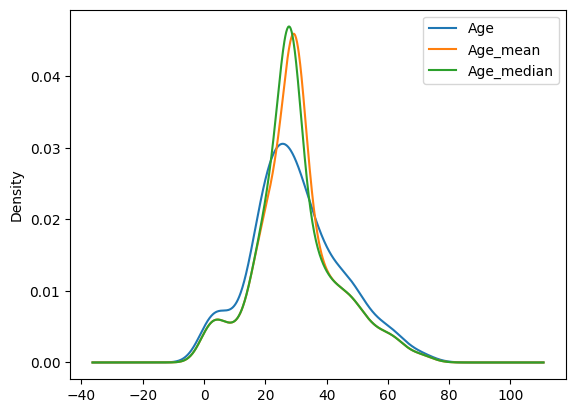

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111)

X_train['Age'].plot(kind = 'kde', ax=ax)
X_train['Age_mean'].plot(kind = 'kde', ax=ax)
X_train['Age_median'].plot(kind = 'kde', ax=ax)

lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

plt.show()

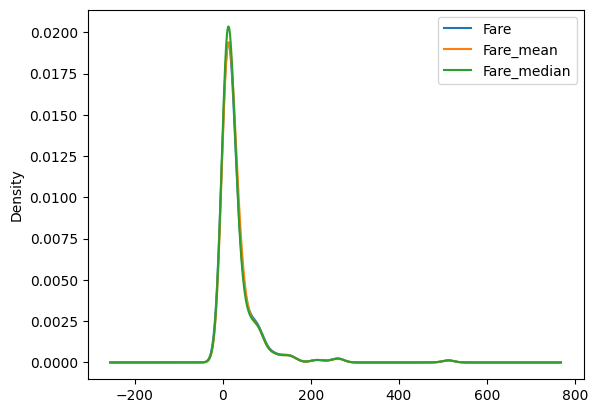

In [14]:
fig = plt.figure()
ax = fig.add_subplot(111)

X_train['Fare'].plot(kind = 'kde', ax=ax)
X_train['Fare_mean'].plot(kind = 'kde', ax=ax)
X_train['Fare_median'].plot(kind = 'kde', ax=ax)

lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

In [15]:
X_train.cov()

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
Age,219.412880,95.204389,-6.023340,219.412880,219.412880,89.822384,88.682617
Fare,95.204389,2567.927687,16.621812,77.038065,81.234779,2567.927687,2567.927687
Family,-6.023340,16.621812,2.266874,-4.761804,-4.644840,15.756787,15.758689
Age_mean,219.412880,77.038065,-4.761804,175.033888,175.199866,73.046536,72.115128
Age_median,219.412880,81.234779,-4.644840,175.199866,175.832298,77.026042,76.031455
Fare_mean,89.822384,2567.927687,15.756787,73.046536,77.026042,2434.299843,2434.005574
Fare_median,88.682617,2567.927687,15.758689,72.115128,76.031455,2434.005574,2449.386816


In [16]:
X_train.corr()

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
Age,1.000000,0.115737,-0.275539,1.000000,1.000000,0.113310,0.111454
Fare,0.115737,1.000000,0.215003,0.114047,0.120001,1.000000,1.000000
Family,-0.275539,0.215003,1.000000,-0.239054,-0.232653,0.212113,0.211484
Age_mean,1.000000,0.114047,-0.239054,1.000000,0.998673,0.111906,0.110138
Age_median,1.000000,0.120001,-0.232653,0.998673,1.000000,0.117734,0.115855
Fare_mean,0.113310,1.000000,0.212113,0.111906,0.117734,1.000000,0.996795
Fare_median,0.111454,1.000000,0.211484,0.110138,0.115855,0.996795,1.000000


<Axes: >

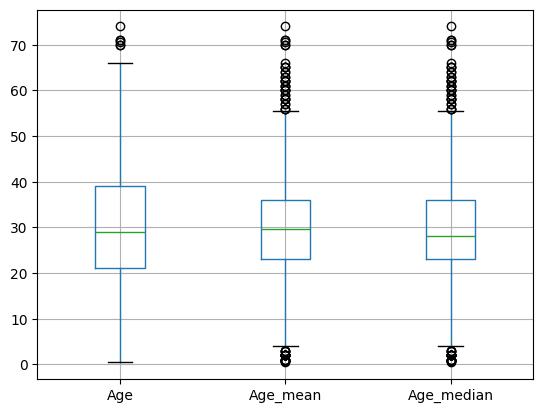

In [19]:
X_train[['Age','Age_mean','Age_median']].boxplot()

<Axes: >

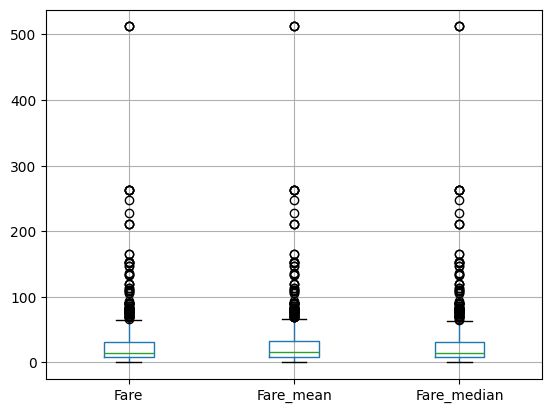

In [21]:
X_train[['Fare','Fare_mean','Fare_median']].boxplot()

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=3)

In [23]:
imputer1 = SimpleImputer(strategy='mean')
imputer2 = SimpleImputer(strategy='median')

In [24]:
trf = ColumnTransformer([
    ('imputer1',imputer1,['Fare']),
    ('imputer2',imputer2,['Age'])
], remainder='passthrough')

In [25]:
trf.fit(X_train)

/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


ColumnTransformer(remainder='passthrough',
                  transformers=[('imputer1', SimpleImputer(), ['Fare']),
                                ('imputer2', SimpleImputer(strategy='median'),
                                 ['Age'])])

In [26]:
X_train = trf.transform(X_train)
X_test = trf.transform(X_test)